# Parte 2 - Algoritmos no grafo do Slashdot

Este notebook reúne a parte de Teoria dos Grafos da Parte 2: amostragem, BFS, DFS, Dijkstra, Bellman-Ford, escalabilidade e relatório de desempenho. A exploração dos dados (AVD) está em `01_exploracao_dados.ipynb`.

## Pergunta de pesquisa

> No Slashdot, quando um usuário marca outro como amigo ou inimigo, como o tipo de marcação se relaciona com o número mínimo de passos para voltar da pessoa marcada até quem fez a marcação?

## 1. Sobre o dataset

O Slashdot é um site de notícias sobre tecnologia. O recurso Slashdot Zoo permite que um usuário marque outro como amigo ou inimigo. O dataset reúne essas relações.

Vamos utilizar o arquivo `soc-sign-Slashdot090221.txt.gz`, de 21 de fevereiro de 2009, disponível no [SNAP / Stanford](https://snap.stanford.edu/data/soc-sign-Slashdot090221.html).

Cada linha representa uma relação de um usuário para outro. Por isso, a rede é dirigida: uma marcação de A para B não significa que B também marcou A.

Além disso, cada marcação tem um peso, que é o seu sinal: `1` para amigo e `-1` para inimigo. Por isso, a rede também é ponderada.

| Coluna | Significado |
| --- | --- |
| `origem` | Identificador do usuário que fez a marcação |
| `destino` | Identificador do usuário que recebeu a marcação |
| `sinal` | `1` para amigo e `-1` para inimigo |

## 2. Preparar a leitura

Selecione o Python do ambiente `.venv` do projeto. O bloco abaixo permite importar `ler_dataset`, a função que já criamos no `io.py`. Ele funciona com o notebook aberto pela raiz do projeto ou pela pasta `notebooks`.

In [1]:
# [IA] ChatGPT - apoio na configuracao dos caminhos para importar o projeto
from pathlib import Path
import sys

import pandas as pd

pasta_projeto = Path.cwd()
if pasta_projeto.name == "notebooks":
    pasta_projeto = pasta_projeto.parent

if str(pasta_projeto) not in sys.path:
    sys.path.insert(0, str(pasta_projeto))

from src.graphs.io import ler_dataset

## 3. Ler o arquivo

O arquivo deve estar em `data/dataset_parte2/`. A função `ler_dataset` abre o `.gz`, ignora os comentários e valida os dados antes de devolver a tabela. Não é necessário descompactar.

`dados.head()` mostra as cinco primeiras linhas, para vermos como as informações estão organizadas.

In [2]:
# [IA] ChatGPT - apoio na leitura e exibicao inicial do dataset
caminho_dataset = pasta_projeto / "data" / "dataset_parte2" / "soc-sign-Slashdot090221.txt.gz"
dados = ler_dataset(caminho_dataset)
dados.head()

,origem,destino,sinal
0,0,1,1
1,0,2,1
2,0,3,1
3,0,4,1
4,0,5,1


## 4. O significado de caminho mínimo e de ciclo negativo no Slashdot

### 4.1 O que representa cada seta

No Slashdot, uma seta de A para B registra uma marcação feita por A sobre B. O sinal +1 indica que A marcou B como amigo, e −1 indica que A marcou B como inimigo.

A direção importa: para saber como B classificou A, precisamos consultar a marcação no sentido contrário, caso ela exista.

### 4.2 O que torna um caminho mínimo

| Algoritmo | Seta de amigo | Seta de inimigo |
| --- | --- | --- |
| BFS | 1 passo | 1 passo |
| Bellman-Ford | +1 | −1 |
| Dijkstra | 1 | 2 |

**BFS (menor número de passos).** Cada seta conta como um passo, qualquer que seja o sinal. Uma sequência de setas de A para B e de B para C indica que A marcou B e B marcou C. Assim, é possível chegar de A a C em dois passos, mas essa sequência, por si só, não permite concluir que A e C sejam amigos.

Um exemplo do projeto é a marcação de amigo de 3451 para 9765. A menor volta encontrada foi de 9765 para 1417 e de 1417 para 3451, em dois passos: o primeiro foi uma marcação de inimigo e o segundo, de amigo.

**Bellman-Ford (sinais originais).** Somamos os sinais. Um custo −2 indica duas marcações de inimigo a mais que as de amigo. Um custo 0 indica quantidades iguais, e +2 indica duas marcações de amigo a mais. Ao minimizar essa soma, o algoritmo favorece percursos em que há mais marcações de inimigo em relação às de amigo, mesmo que tenham mais passos.

**Dijkstra (amigo 1, inimigo 2).** Escolhemos pesos positivos porque o algoritmo exige pesos não negativos. Cada passo custa 1, com um acréscimo de 1 quando a marcação é de inimigo. Assim, uma seta de inimigo aumenta o custo em 2 no Dijkstra e reduz o custo em 1 no Bellman-Ford. A escolha permite considerar tanto o número de passos quanto o tipo de marcação. Por essa regra, passar por duas setas de amigo custa o mesmo que passar por uma de inimigo.

### 4.3 O que significa o ciclo negativo

Na rede completa, o ciclo de 919 para 949 e de volta para 919 mostra que os dois usuários se marcaram como inimigos. Cada seta vale −1, portanto uma volta completa soma −2.

O usuário 11038 consegue chegar a esse ciclo pelo caminho de 11038 para 8 e de 8 para 919. A partir de 919, cada volta extra reduz o custo em mais 2. Por isso, para qualquer destino que possa ser alcançado depois de passar pelo ciclo, não existe custo mínimo finito a partir de 11038: sempre é possível dar mais uma volta antes de seguir até o destino.

Na rede social, dar outra volta significa contar de novo as mesmas duas marcações. Nenhum dos usuários fez uma nova marcação, e a repetição não indica que a inimizade ficou mais forte.

### 4.4 Limites dos pesos

Os sinais +1 e −1 identificam duas categorias. No Bellman-Ford, somá-los é uma escolha do grupo para comparar a quantidade de marcações de cada tipo ao longo de um percurso. Por exemplo, um custo zero pode resultar de uma marcação de amigo seguida de uma de inimigo. Esse equilíbrio na contagem não permite dizer que os usuários das pontas sejam indiferentes um ao outro.

A base também não informa a intensidade nem a data de cada marcação. Por isso, a ordem das setas mostra como percorrer a rede, sem indicar em que ordem as pessoas fizeram as marcações.

## 5. Amostragem para os experimentos

A exploração utiliza a rede completa. Os experimentos usam recortes com 10%, 50% e 100% dos usuários. Os identificadores são ordenados e embaralhados com a semente 42, e cada recorte usa o início da mesma lista, mantendo os menores contidos nos maiores. O subgrafo induzido preserva os nós selecionados e os arcos entre eles, com sua direção e sinal.

Os percentuais se referem aos nós, não aos arcos, e 100% corresponde à rede original. Os recortes podem ficar desconectados, e seus graus, caminhos e ciclos não devem ser generalizados para a rede completa.

In [3]:
# [IA] ChatGPT - apoio na implementacao dos recortes reproduziveis
import random

from src.graphs.io import montar_grafo_dataset

semente = 42
percentuais = [10, 50, 100]
grafo_completo = montar_grafo_dataset(dados)

usuarios_sorteados = sorted(grafo_completo.nos())
random.Random(semente).shuffle(usuarios_sorteados)

recortes = {}
resumo_recortes = []

for percentual in percentuais:
    quantidade = grafo_completo.ordem() * percentual // 100
    recorte = grafo_completo.subgrafo_induzido(usuarios_sorteados[:quantidade])

    recortes[percentual] = recorte
    resumo_recortes.append({
        "usuarios (%)": percentual,
        "nos": recorte.ordem(),
        "arcos": recorte.tamanho(),
        "arcos (%)": round(recorte.tamanho() / grafo_completo.tamanho() * 100, 2),
    })

pd.DataFrame(resumo_recortes).set_index("usuarios (%)")

,nos,arcos,arcos (%)
usuarios (%),,,
10,8214,5434,0.99
50,41070,134558,24.50
100,82140,549202,100.00


**Interpretação**

O recorte de 10% preservou 5.434 arcos (0,99% do total). O de 50% preservou 134.558 (24,50%). Um arco só entra no recorte quando seus dois usuários foram selecionados. Por isso, os percentuais de usuários e de arcos são diferentes. O recorte de 100% preservou os 549.202 arcos.

## 6. Buscas BFS e DFS no Slashdot

Nesta seção, usamos as duas buscas para duas tarefas. Primeiro, verificamos se existe caminho de volta para algumas marcações na rede completa. Depois, medimos quantos usuários as buscas alcançam e quanto tempo levam nos recortes de 10%, 50% e 100%.

Se A marcou B, a volta começa em B e procura A seguindo o sentido das setas. O tipo, amigo ou inimigo, é o da marcação original. Tanto as setas de amigo quanto as de inimigo podem fazer parte da volta, e cada seta conta como um passo.

### 6.1 BFS (busca em largura)

A BFS procura em camadas. Primeiro visita quem está a um passo, depois quem está a dois, e assim por diante. A primeira vez que encontra quem fez a marcação indica a menor distância de volta.

Sorteamos cinco marcações de amigo e cinco de inimigo, sem reposição e com semente 42. Esses dez casos ajudam a conferir a medição.

**Como ler a tabela**

- **Marcação original** mostra quem marcou e quem recebeu, nessa ordem.
- **Tipo** indica se a marcação original foi de amigo ou inimigo.
- **Menor caminho de volta** mostra a sequência de usuários, de quem recebeu até quem marcou.
- **Passos** conta as setas do caminho de volta. Se não houver caminho, aparece um traço.

In [4]:
# [IA] ChatGPT - apoio no uso da BFS do projeto e na tabela do piloto
from src.graphs.algorithms import bfs, montar_caminho

marcacoes_piloto = pd.concat([
    dados.loc[dados["sinal"] == 1].sample(n=5, random_state=42),
    dados.loc[dados["sinal"] == -1].sample(n=5, random_state=42),
], ignore_index=True)

resultados_retorno = []
for origem, destino, sinal in marcacoes_piloto.itertuples(index=False, name=None):
    _, pais, _ = bfs(grafo_completo, destino)
    caminho = montar_caminho(pais, origem)
    resultados_retorno.append({
        "Marcação original": f"{origem} → {destino}",
        "Tipo": "Amigo" if sinal == 1 else "Inimigo",
        "Menor caminho de volta": " → ".join(map(str, caminho)) if caminho else "Sem caminho",
        "Passos": len(caminho) - 1 if caminho else None,
    })

piloto_retorno = pd.DataFrame(resultados_retorno)
piloto_retorno["Passos"] = piloto_retorno["Passos"].astype("Int64")
piloto_retorno.assign(Passos=piloto_retorno["Passos"].astype("string").fillna("—"))

,Marcação original,Tipo,Menor caminho de volta,Passos
0,8068 → 48080,Amigo,Sem caminho,—
1,653 → 19563,Amigo,19563 → 6712 → 21537 → 653,3
2,3451 → 9765,Amigo,9765 → 1417 → 3451,2
3,21299 → 134,Amigo,134 → 8 → 50 → 1723 → 21299,4
4,7733 → 11021,Amigo,11021 → 1935 → 686 → 7733,3
5,19236 → 16592,Inimigo,16592 → 68 → 1870 → 19236,3
6,3381 → 29495,Inimigo,29495 → 18596 → 11810 → 3217 → 3245 → 3381,5
7,19094 → 3078,Inimigo,3078 → 19094,1
8,65476 → 277,Inimigo,277 → 191 → 330 → 8193 → 53864 → 65476,5
9,47238 → 36599,Inimigo,36599 → 7191 → 662 → 3338 → 47238,4


**Interpretação**

Para a marcação de amigo de **3451** para **9765**, o menor caminho de volta vai de **9765** para **1417** e de **1417** para **3451**. São dois passos porque há duas setas e uma pessoa intermediária. A primeira seta da volta é de inimigo e a segunda, de amigo.

Das dez marcações sorteadas, nove tiveram volta e uma ficou sem caminho. Essa contagem descreve apenas o piloto. A comparação entre amigo e inimigo precisa de mais casos.

### 6.2 DFS (busca em profundidade)

A DFS segue um ramo até onde consegue. Quando ele acaba, volta ao último ponto com uma opção por explorar. Assim como a BFS, ela encontra o destino se ele estiver ao alcance da fonte. O caminho que ela monta depende da ordem dos vizinhos.

Usamos duas marcações da tabela anterior, uma com volta e outra sem. A coluna “Há retorno?” indica se ambas encontraram um caminho. As outras colunas mostram quantos passos cada caminho tem. Para responder à pergunta de pesquisa, usamos a distância da BFS, que garante a menor volta.

In [5]:
# [IA] ChatGPT - apoio no uso da DFS do projeto na comparação com a BFS
from src.graphs.algorithms import dfs

comparacao_buscas = []
# Linhas do piloto com retorno (2) e sem retorno (0).
for exemplo in (2, 0):
    origem, destino, _ = marcacoes_piloto.loc[exemplo]
    pais_dfs, _, _, _ = dfs(grafo_completo, origem=destino)
    caminho_dfs = montar_caminho(pais_dfs, origem)
    passos_bfs = piloto_retorno.loc[exemplo, "Passos"]
    assert (caminho_dfs is not None) == pd.notna(passos_bfs)

    comparacao_buscas.append({
        "Marcação original": f"{origem} → {destino}",
        "Há retorno?": "Sim" if caminho_dfs else "Não",
        "BFS (passos)": passos_bfs,
        "DFS (passos)": len(caminho_dfs) - 1 if caminho_dfs else None,
    })

tabela_buscas = pd.DataFrame(comparacao_buscas)
colunas_passos = ["BFS (passos)", "DFS (passos)"]
tabela_buscas[colunas_passos] = tabela_buscas[colunas_passos].astype("Int64")
tabela_buscas.astype({coluna: "string" for coluna in colunas_passos}).fillna("—")

,Marcação original,Há retorno?,BFS (passos),DFS (passos)
0,3451 → 9765,Sim,2,775
1,8068 → 48080,Não,—,—


**Interpretação**

As duas buscas concordaram nos dois exemplos sobre a existência de retorno. Na marcação de 3451 para 9765, a BFS encontrou a volta em 2 passos e a DFS registrou um caminho de 775. Os dois caminhos chegam ao mesmo usuário. Para medir a menor distância, usamos os 2 passos garantidos pela BFS. O caminho da DFS depende da ordem em que ela explora os vizinhos.

### 6.3 Comparação nas amostragens de 10%, 50% e 100%

Nos blocos 6.1 e 6.2, usamos a rede completa para medir o caminho de volta de marcações específicas. Aqui, a pergunta é como o tamanho do grafo afeta o alcance e o tempo das buscas. Usamos os recortes de 10%, 50% e 100% dos usuários criados na seção 5.

Para comparar os três tamanhos, usamos os mesmos três usuários de partida. Sorteamos os pontos de partida entre os usuários do recorte de 10% que têm pelo menos uma seta de saída nesse recorte, com semente 42. Como os recortes menores estão contidos nos maiores, esses usuários aparecem nos três tamanhos.

In [6]:
# [IA] ChatGPT - apoio no sorteio reproduzível das fontes
candidatos = sorted(
    usuario for usuario in recortes[10].nos()
    if recortes[10].grau_saida(usuario) > 0
)
fontes_buscas = random.Random(42).sample(candidatos, 3)

#### 6.3.1 Medição das buscas

Executamos cada busca cinco vezes para cada usuário de partida e cada recorte. A tabela mostra o tempo mediano: o valor do meio quando ordenamos as cinco medições. Medimos apenas as chamadas de BFS e DFS. A montagem dos recortes e a conferência dos resultados ficam fora do cronômetro.

**Como ler as colunas**

- **Usuário de partida** é o ID da pessoa de onde a busca começa.
- **Máximo de passos (BFS)** mostra o maior número de passos entre os menores caminhos do usuário de partida até os usuários alcançados. Cada seta conta como um passo.
- **Máximo de passos (DFS)** conta os passos do ramo mais profundo registrado pela DFS a partir do usuário de partida. A DFS segue um ramo de cada vez, por isso esse caminho pode ter bem mais passos que o menor caminho até o mesmo usuário.

In [7]:
# [IA] ChatGPT - apoio na medição da BFS e da DFS nos recortes
from collections import Counter
from statistics import median
from time import perf_counter

from src.graphs.algorithms import bfs, dfs

buscas = [("BFS", bfs), ("DFS", dfs)]
linhas_escalabilidade = []
for percentual, grafo in recortes.items():
    for fonte in fontes_buscas:
        tempos = {"BFS": [], "DFS": []}
        for repeticao in range(5):
            ordem_buscas = buscas if repeticao % 2 == 0 else buscas[::-1]
            for nome, busca in ordem_buscas:
                inicio = perf_counter()
                resultado = busca(grafo, fonte)
                tempos[nome].append((perf_counter() - inicio) * 1000)
                if nome == "BFS":
                    distancias, _, ordem_bfs = resultado
                else:
                    pais_dfs, ordem_dfs, _, tem_ciclo = resultado
                del resultado
            assert set(ordem_bfs) == set(ordem_dfs), "As buscas alcançaram usuários diferentes"

        # Na ordem de visita, o usuário anterior no caminho já tem profundidade calculada.
        passos_dfs = {fonte: 0}
        for usuario in ordem_dfs[1:]:
            passos_dfs[usuario] = passos_dfs[pais_dfs[usuario]] + 1

        linhas_escalabilidade.append({
            "Recorte (%)": percentual,
            "Nós": grafo.ordem(),
            "Arcos": grafo.tamanho(),
            "Usuário de partida": fonte,
            "Alcançados": len(ordem_bfs),
            "Máximo de passos (BFS)": max(distancias.values()),
            "Máximo de passos (DFS)": max(passos_dfs.values()),
            "Ciclo (DFS)": "Sim" if tem_ciclo else "Não",
            "BFS (ms)": median(tempos["BFS"]),
            "DFS (ms)": median(tempos["DFS"]),
            "Usuários por camada BFS": dict(sorted(Counter(distancias.values()).items())),
            "Primeiros 10 da BFS": ordem_bfs[:10],
            "Primeiros 10 da DFS": ordem_dfs[:10],
            "Tempos BFS por execução": tempos["BFS"],
            "Tempos DFS por execução": tempos["DFS"],
        })

escalabilidade_buscas = pd.DataFrame(linhas_escalabilidade)
resumo_buscas = escalabilidade_buscas[[
    "Recorte (%)", "Usuário de partida",
    "Máximo de passos (BFS)", "Máximo de passos (DFS)", "BFS (ms)", "DFS (ms)",
]].round({"BFS (ms)": 3, "DFS (ms)": 3})
resumo_buscas

,Recorte (%),Usuário de partida,Máximo de passos (BFS),Máximo de passos (DFS),BFS (ms),DFS (ms)
0,10,48088,10,108,1.766,4.557
1,10,4710,1,1,0.002,0.003
2,10,1199,9,111,1.444,5.602
3,50,48088,9,2232,57.785,167.838
4,50,4710,8,2205,41.257,135.293
5,50,1199,8,2223,36.605,116.178
6,100,48088,9,6636,141.178,552.094
7,100,4710,9,6591,143.366,511.677
8,100,1199,8,6498,133.310,536.146


**Interpretação**

As duas buscas alcançaram os mesmos usuários nos nove casos. Mesmo assim, os caminhos registrados têm tamanhos diferentes. Na rede completa, partindo de 48088, todos os usuários alcançáveis estavam a até 9 passos pela BFS. A DFS registrou um ramo de 6.636 passos. Os dois máximos podem corresponder a usuários diferentes.

As medianas de tempo aumentaram com o tamanho dos recortes para os três usuários testados. A medição da DFS inclui a classificação dos arcos e a detecção de ciclos. A tabela detalhada `escalabilidade_buscas` guarda também o total de alcançados, as camadas da BFS, a ordem inicial de visita, os ciclos e os tempos individuais.

#### 6.3.2 Camadas, ordem de visita e ciclos

A tabela da seção 6.3.1 mostra só o máximo de passos e os tempos. Aqui mostramos, para os mesmos três usuários de partida e os três recortes, o que as buscas encontraram, em duas tabelas. A primeira traz as camadas da BFS: quantos usuários ficam a cada número de passos da origem, com os três primeiros de cada passo. A segunda traz a ordem em que a BFS e a DFS visitam os dez primeiros usuários e se a DFS encontrou algum ciclo. A origem fica fora das camadas, porque está a zero passos. Nenhum tempo é medido de novo: a BFS só é executada outra vez para listar os usuários de cada passo.

In [26]:
# [IA] Claude - apoio na tabela de camadas, ordem e ciclos da BFS e da DFS
from IPython.display import HTML, display


def formatar_numero(valor):
    return f"{valor:,}".replace(",", ".")


linhas_camadas = []
linhas_ordem = []
for _, linha in escalabilidade_buscas.iterrows():
    distancias, _, ordem_bfs = bfs(recortes[linha["Recorte (%)"]], linha["Usuário de partida"])
    camadas = []
    for passo in range(1, max(distancias.values()) + 1):
        usuarios = [usuario for usuario in ordem_bfs if distancias[usuario] == passo]
        palavra = "usuário" if len(usuarios) == 1 else "usuários"
        reticencias = ", …" if len(usuarios) > 3 else ""
        camadas.append(
            f"Passo {passo} ({formatar_numero(len(usuarios))} {palavra}): "
            f"{', '.join(map(str, usuarios[:3]))}{reticencias}"
        )
    linhas_camadas.append({
        "Recorte (%)": linha["Recorte (%)"],
        "Usuário de partida": linha["Usuário de partida"],
        "Alcançados": formatar_numero(linha["Alcançados"]),
        "Camadas da BFS (3 primeiros de cada passo)": "<br>".join(camadas),
    })
    linhas_ordem.append({
        "Recorte (%)": linha["Recorte (%)"],
        "Usuário de partida": linha["Usuário de partida"],
        "Primeiros 10 da BFS": ", ".join(map(str, linha["Primeiros 10 da BFS"])),
        "Primeiros 10 da DFS": ", ".join(map(str, linha["Primeiros 10 da DFS"])),
        "Ciclo (DFS)": linha["Ciclo (DFS)"],
    })

display(
    HTML(pd.DataFrame(linhas_camadas).to_html(escape=False, index=False)),
    HTML(pd.DataFrame(linhas_ordem).to_html(escape=False, index=False)),
)

Recorte (%),Usuário de partida,Alcançados,Camadas da BFS (3 primeiros de cada passo)
10,48088,1.412,"Passo 1 (3 usuários): 2695, 8501, 17641Passo 2 (16 usuários): 90, 639, 846, …Passo 3 (93 usuários): 1011, 1060, 1247, …Passo 4 (346 usuários): 896, 1808, 4723, …Passo 5 (502 usuários): 39400, 4698, 6762, …Passo 6 (270 usuários): 4710, 4718, 4724, …Passo 7 (110 usuários): 49248, 13721, 33642, …Passo 8 (50 usuários): 4120, 11888, 18428, …Passo 9 (15 usuários): 16357, 9494, 15913, …Passo 10 (6 usuários): 7183, 19123, 24731, …"
10,4710,2,Passo 1 (1 usuário): 49248
10,1199,1.411,"Passo 1 (14 usuários): 101, 811, 846, …Passo 2 (133 usuários): 56, 111, 745, …Passo 3 (382 usuários): 11072, 11075, 90, …Passo 4 (423 usuários): 858, 4046, 2070, …Passo 5 (286 usuários): 9091, 9203, 17354, …Passo 6 (110 usuários): 10485, 7301, 40333, …Passo 7 (45 usuários): 3755, 73942, 5079, …Passo 8 (11 usuários): 15913, 29911, 29919, …Passo 9 (6 usuários): 7183, 19123, 24731, …"
50,48088,23.123,"Passo 1 (8 usuários): 981, 2245, 2695, …Passo 2 (105 usuários): 112, 930, 2029, …Passo 3 (1.833 usuários): 115, 330, 530, …Passo 4 (9.348 usuários): 149, 218, 580, …Passo 5 (9.167 usuários): 4846, 10569, 11853, …Passo 6 (2.225 usuários): 49518, 64864, 64868, …Passo 7 (396 usuários): 21453, 77248, 64523, …Passo 8 (39 usuários): 48133, 48137, 48138, …Passo 9 (1 usuário): 15556"
50,4710,23.120,"Passo 1 (6 usuários): 2895, 2917, 3326, …Passo 2 (87 usuários): 622, 874, 957, …Passo 3 (1.814 usuários): 9, 17, 58, …Passo 4 (9.267 usuários): 49, 118, 134, …Passo 5 (9.093 usuários): 808, 7540, 21342, …Passo 6 (2.433 usuários): 20921, 63572, 63350, …Passo 7 (386 usuários): 57379, 57381, 75325, …Passo 8 (33 usuários): 77879, 69211, 69212, …"
50,1199,23.120,"Passo 1 (56 usuários): 14, 60, 66, …Passo 2 (1.483 usuários): 0, 17, 29, …Passo 3 (9.478 usuários): 2, 6, 10, …Passo 4 (9.255 usuários): 768, 961, 964, …Passo 5 (2.402 usuários): 25210, 38065, 38066, …Passo 6 (407 usuários): 74128, 17122, 17123, …Passo 7 (37 usuários): 81268, 43925, 43926, …Passo 8 (1 usuário): 75781"
100,48088,67.272,"Passo 1 (22 usuários): 636, 672, 734, …Passo 2 (722 usuários): 1, 62, 86, …Passo 3 (13.487 usuários): 4, 9, 31, …Passo 4 (37.422 usuários): 700, 943, 944, …Passo 5 (13.726 usuários): 19020, 21683, 21687, …Passo 6 (1.699 usuários): 67737, 79922, 62378, …Passo 7 (178 usuários): 77533, 81731, 79984, …Passo 8 (13 usuários): 77295, 77297, 80765, …Passo 9 (2 usuários): 66322, 50012"
100,4710,67.266,"Passo 1 (15 usuários): 27, 2895, 2917, …Passo 2 (270 usuários): 74, 80, 125, …Passo 3 (8.558 usuários): 9, 47, 50, …Passo 4 (36.085 usuários): 49, 118, 140, …Passo 5 (19.243 usuários): 38081, 38195, 38196, …Passo 6 (2.796 usuários): 4647, 4648, 4649, …Passo 7 (267 usuários): 60328, 9562, 81772, …Passo 8 (27 usuários): 57039, 82005, 13133, …Passo 9 (4 usuários): 74035, 82136, 66322, …"
100,1199,67.266,"Passo 1 (103 usuários): 11, 14, 60, …Passo 2 (4.417 usuários): 0, 5, 8, …Passo 3 (32.434 usuários): 2, 6, 10, …Passo 4 (25.475 usuários): 765, 768, 961, …Passo 5 (4.322 usuários): 71015, 71016, 20714, …Passo 6 (469 usuários): 73949, 73950, 73951, …Passo 7 (43 usuários): 81716, 81898, 80878, …Passo 8 (2 usuários): 65971, 50012"


Recorte (%),Usuário de partida,Primeiros 10 da BFS,Primeiros 10 da DFS,Ciclo (DFS)
10,48088,"48088, 2695, 8501, 17641, 90, 639, 846, 2418, 3074, 4694","48088, 2695, 90, 639, 1011, 896, 1005, 168, 1935, 1069",Sim
10,4710,"4710, 49248","4710, 49248",Sim
10,1199,"1199, 101, 811, 846, 1051, 1055, 1088, 1159, 1203, 1233","1199, 101, 56, 9, 11072, 858, 6234, 11075, 111, 745",Sim
50,48088,"48088, 981, 2245, 2695, 8501, 12926, 17641, 48090, 48091, 112","48088, 981, 112, 115, 330, 149, 47, 17, 0, 2",Sim
50,4710,"4710, 2895, 2917, 3326, 5878, 6283, 49248, 622, 874, 957","4710, 2895, 622, 9, 17, 0, 2, 6, 31, 172",Sim
50,1199,"1199, 14, 60, 66, 69, 72, 87, 92, 101, 640","1199, 14, 0, 2, 6, 31, 172, 754, 764, 767",Sim
100,48088,"48088, 636, 672, 734, 981, 1052, 2245, 2506, 2695, 3014","48088, 636, 672, 1, 0, 2, 3, 8, 9, 17",Sim
100,4710,"4710, 27, 2895, 2917, 3326, 3813, 5209, 5878, 6283, 9382","4710, 27, 2895, 74, 9, 17, 0, 1, 4, 700",Sim
100,1199,"1199, 11, 14, 60, 66, 67, 69, 70, 71, 72","1199, 11, 0, 1, 4, 700, 9, 17, 3, 8",Sim


**Interpretação**

Nas três origens, o número de usuários por passo começa pequeno, cresce até os passos intermediários, onde fica o maior grupo, e volta a diminuir nos últimos passos, que reúnem poucos usuários. Quanto maior o recorte, mais usuários são alcançados (a partir de 48088, 1.412, 23.123 e 67.272), mas o número máximo de passos quase não muda: fica em 10 ou menos em todas as combinações. A exceção é a origem 4710 no recorte de 10%, que alcança só 2 usuários, um deles a 1 passo.

A BFS e a DFS partem da mesma origem, mas visitam os usuários em ordens diferentes: a BFS termina os vizinhos da origem antes de avançar, e a DFS segue um ramo em profundidade. Por isso, nas combinações com mais de dois usuários alcançados, as duas listas se separam logo no começo, no terceiro ou no quarto usuário visitado, contando a origem. A DFS também encontrou ciclo em todas as combinações, o que mostra que a rede tem ciclos alcançáveis a partir das três origens, nos três recortes.

## 7. Dijkstra no Slashdot

O Dijkstra não aceita pesos negativos. Por isso, ele não pode usar diretamente os sinais +1 e −1 do dataset (seção 4.6 do notebook `01_exploracao_dados.ipynb`). Nesta seção, transformamos os pesos assim:

| Marcação | Sinal no dataset | Peso no Dijkstra |
| --- | --- | --- |
| Amigo | +1 | 1 |
| Inimigo | −1 | 2 |

Cada seta continua valendo pelo menos um passo, e a seta de inimigo custa o dobro. Assim, o custo de um caminho é o número de passos somado ao número de setas de inimigo. Um passo a mais custa o mesmo que uma seta de inimigo, então o Dijkstra pode escolher uma volta mais longa se ela usar menos setas de inimigo.

Essa transformação muda os caminhos mínimos: o caminho de menor custo pode ter mais passos que o caminho da BFS. A célula abaixo cria, para cada recorte da seção 5, uma cópia do grafo com esses pesos. Os arcos, a direção e a ordem dos vizinhos continuam os mesmos.

In [8]:
# [IA] Claude – transformação dos pesos para o Dijkstra (amigo 1, inimigo 2)
from collections import Counter

from src.graphs.graph import GrafoDirigido

PESO_DIJKSTRA = {1: 1, -1: 2}


def grafo_com_pesos_dijkstra(grafo):
    novo = GrafoDirigido(grafo.nome + "_dijkstra")
    for usuario in grafo.nos():
        novo.adicionar_no(usuario)
    for origem in grafo.nos():
        for destino, sinal, _, _ in grafo.vizinhos(origem):
            novo.adicionar_arco(origem, destino, peso=PESO_DIJKSTRA[sinal])
    return novo


recortes_dijkstra = {percentual: grafo_com_pesos_dijkstra(grafo) for percentual, grafo in recortes.items()}

# conferência: na rede completa, os pesos 1 e 2 devem repetir a contagem de amigos e inimigos da seção 4.6 do notebook 01_exploracao_dados
contagem_pesos = Counter(
    peso
    for usuario in recortes_dijkstra[100].nos()
    for _, peso, _, _ in recortes_dijkstra[100].vizinhos(usuario)
)
pd.Series(
    {
        "arcos com peso 1 (amigo)": contagem_pesos[1],
        "arcos com peso 2 (inimigo)": contagem_pesos[2],
        "arcos com peso negativo": sum(n for peso, n in contagem_pesos.items() if peso < 0),
    },
    name="quantidade",
).to_frame()

,quantidade
arcos com peso 1 (amigo),425072
arcos com peso 2 (inimigo),124130
arcos com peso negativo,0


### 7.1 Volta das marcações do piloto

Usamos as mesmas dez marcações da seção 6.1, cinco de amigo e cinco de inimigo. Para cada marcação de A para B, o Dijkstra começa em B e calcula o menor custo de volta até A na rede completa. Assim, comparamos a volta de menor custo com a volta de menos passos encontrada pela BFS.

Executamos o Dijkstra cinco vezes para cada marcação e mostramos o tempo médio. Medimos apenas as chamadas do Dijkstra. Cada chamada calcula o custo de B até todos os usuários que ele alcança, e não só até A.

**Como ler as colunas**

- **Passos (BFS)** repete o menor número de passos da seção 6.1.
- **Custo (Dijkstra)** é a soma dos pesos da volta de menor custo.
- **Passos (Dijkstra)** conta as setas dessa volta.
- **Setas de inimigo** conta quantas setas de inimigo a volta usa. Como cada seta de inimigo vale 2, esse número é o custo menos os passos.
- **Volta pelo Dijkstra** mostra a sequência de usuários, de quem recebeu a marcação até quem a fez.
- **Tempo médio (ms)** é a média das cinco execuções, em milissegundos.

In [9]:
# [IA] Claude – Dijkstra nas marcações do piloto, com conferência e tempo médio
from statistics import mean, median
from time import perf_counter

from src.graphs.algorithms import dijkstra, montar_caminho

grafo_dijkstra = recortes_dijkstra[100]
linhas_dijkstra = []
for (origem, destino, sinal), passos_bfs in zip(
    marcacoes_piloto.itertuples(index=False, name=None), piloto_retorno["Passos"]
):
    tempos = []
    for _ in range(5):
        inicio = perf_counter()
        distancias, pais, _ = dijkstra(grafo_dijkstra, destino)
        tempos.append((perf_counter() - inicio) * 1000)

    caminho = montar_caminho(pais, origem)
    # o Dijkstra e a BFS precisam concordar sobre a existência da volta
    assert (caminho is not None) == pd.notna(passos_bfs)
    custo = distancias[origem] if caminho else None
    passos = len(caminho) - 1 if caminho else None

    linhas_dijkstra.append({
        "Marcação original": f"{origem} → {destino}",
        "Tipo": "Amigo" if sinal == 1 else "Inimigo",
        "Passos (BFS)": passos_bfs,
        "Custo (Dijkstra)": custo,
        "Passos (Dijkstra)": passos,
        "Setas de inimigo": custo - passos if caminho else None,
        "Volta pelo Dijkstra": " → ".join(map(str, caminho)) if caminho else "Sem caminho",
        "Tempo médio (ms)": mean(tempos),
        "Tempos por execução (ms)": tempos,
    })

pares_dijkstra = pd.DataFrame(linhas_dijkstra)
colunas_inteiras = ["Passos (BFS)", "Custo (Dijkstra)", "Passos (Dijkstra)", "Setas de inimigo"]
pares_dijkstra[colunas_inteiras] = pares_dijkstra[colunas_inteiras].astype("Int64")
(
    pares_dijkstra.drop(columns="Tempos por execução (ms)")
    .astype({coluna: "string" for coluna in colunas_inteiras})
    .fillna("—")
    .round({"Tempo médio (ms)": 1})
)

,Marcação original,Tipo,Passos (BFS),Custo (Dijkstra),Passos (Dijkstra),Setas de inimigo,Volta pelo Dijkstra,Tempo médio (ms)
0,8068 → 48080,Amigo,—,—,—,—,Sem caminho,0.9
1,653 → 19563,Amigo,3,3,3,0,19563 → 6712 → 21537 → 653,384.1
2,3451 → 9765,Amigo,2,2,2,0,9765 → 4204 → 3451,398.4
3,21299 → 134,Amigo,4,4,4,0,134 → 8 → 83 → 2920 → 21299,496.9
4,7733 → 11021,Amigo,3,4,3,1,11021 → 1935 → 686 → 7733,381.5
5,19236 → 16592,Inimigo,3,3,3,0,16592 → 197 → 5199 → 19236,325.4
6,3381 → 29495,Inimigo,5,6,6,0,29495 → 18596 → 11810 → 79 → 170 → 23840 → 3381,275.9
7,19094 → 3078,Inimigo,1,2,1,1,3078 → 19094,341.4
8,65476 → 277,Inimigo,5,6,5,1,277 → 191 → 330 → 8193 → 53864 → 65476,305.7
9,47238 → 36599,Inimigo,4,4,4,0,36599 → 7191 → 662 → 3338 → 47238,299.5


**Interpretação**

Das 10 marcações testadas, nove tiveram volta nos dois algoritmos, o que cumpre o mínimo de cinco pares. A exceção foi a marcação de **8068** para **48080**, porque nenhuma seta sai de 48080.

Os pesos alongaram apenas a volta da marcação de **3381** para **29495**. A volta da BFS tinha 5 passos e 2 setas de inimigo, com custo 7, e a do Dijkstra tinha 6 passos, só por setas de amigo, com custo 6. Em outras três marcações, o número de passos se manteve, mas o caminho mudou. Na marcação de **3451** para **9765**, por exemplo, voltar por 1417 custaria 3, e por 4204 custou 2. Três voltas mantiveram uma seta de inimigo, porque nenhuma outra custava menos.

Cada chamada calcula o custo até todos os usuários alcançáveis a partir de quem recebeu a marcação. Por isso, a volta de um passo levou 341,4 ms, mais que a de seis, com 275,9 ms. Dez marcações mostram um caso em que os pesos tornaram a volta mais longa e mais barata, mas não bastam para estimar com que frequência isso ocorre na rede inteira.

## 8. Bellman-Ford no Slashdot

O Bellman-Ford aceita pesos negativos, então aqui usamos os sinais originais do dataset: +1 para amigo e −1 para inimigo. Com esses pesos, o custo de um caminho é o número de setas de amigo menos o número de setas de inimigo.

Um ciclo negativo é um ciclo com mais setas de inimigo do que de amigo. O menor exemplo é o ciclo de A para B e de volta para A, quando os dois usuários se marcaram como inimigos: o custo do ciclo é −2. Se um usuário consegue chegar a um ciclo negativo, o menor custo até os usuários alcançáveis a partir desse ciclo deixa de existir, porque cada volta extra no ciclo diminui o custo.

A implementação do projeto confere, a cada rodada, se os ponteiros de pai formam um ciclo. Quando isso acontece, ela para e devolve o ciclo encontrado.

Para mostrar os dois casos, usamos o mesmo usuário de partida em dois tamanhos do grafo:

1. No recorte de 10%, a partir dele há setas de inimigo, mas nenhum ciclo negativo. O Bellman-Ford termina e calcula todos os custos.
2. Na rede completa, a partir do mesmo usuário, o Bellman-Ford encontra um ciclo negativo.

Para escolher esse usuário, rodamos o Bellman-Ford a partir de cada usuário do recorte de 10%. Ficamos com os que não chegaram a um ciclo negativo e alcançaram pelo menos um custo negativo. Entre eles, escolhemos o que alcança mais usuários (no empate, o menor ID) e que, na rede completa, chega a um ciclo negativo.

In [10]:
# [IA] Claude – escolha do usuário de partida para os dois casos do Bellman-Ford
from src.graphs.algorithms import bellman_ford, bfs, custo_caminho

candidatos_bf = []
for usuario in sorted(recortes[10].nos()):
    distancias, _, ciclo = bellman_ford(recortes[10], usuario)
    if ciclo is None and min(distancias.values()) < 0:
        candidatos_bf.append((usuario, len(distancias)))

# mais usuários alcançados primeiro; no empate, o menor ID
candidatos_bf.sort(key=lambda candidato: (-candidato[1], candidato[0]))
fonte_bf = next(
    usuario for usuario, _ in candidatos_bf
    if bellman_ford(recortes[100], usuario)[2] is not None
)
print(f"Usuários do recorte de 10% sem ciclo negativo e com algum custo negativo: {len(candidatos_bf)}")
print(f"Usuário de partida escolhido: {fonte_bf}")

Usuários do recorte de 10% sem ciclo negativo e com algum custo negativo: 136
Usuário de partida escolhido: 11038


### 8.1 Caso com peso negativo e sem ciclo negativo (recorte de 10%)

Rodamos o Bellman-Ford cinco vezes a partir do usuário escolhido, no recorte de 10% e com os pesos originais. A tabela mostra cada usuário alcançado, o custo calculado e o caminho de menor custo, com o sinal de cada seta. Antes da tabela aparecem o total de alcançados, as setas de inimigo que saem desses usuários e o tempo médio.

**Como ler as colunas**

- **Custo** é a soma dos sinais do caminho: cada seta de amigo soma 1 e cada seta de inimigo subtrai 1.
- **Caminho** mostra a sequência de usuários a partir do usuário de partida.
- **Sinais** mostra o sinal de cada seta do caminho, na mesma ordem.

In [11]:
# [IA] Claude – Bellman-Ford sem ciclo negativo no recorte de 10%
def sinal_do_arco(grafo, origem, destino):
    return next(peso for vizinho, peso, _, _ in grafo.vizinhos(origem) if vizinho == destino)


def medir_bellman_ford(grafo, fonte, repeticoes=5):
    tempos = []
    for _ in range(repeticoes):
        inicio = perf_counter()
        resultado = bellman_ford(grafo, fonte)
        tempos.append((perf_counter() - inicio) * 1000)
    return resultado, tempos


(distancias_bf, pais_bf, ciclo_bf), tempos_bf_sem_ciclo = medir_bellman_ford(recortes[10], fonte_bf)
assert ciclo_bf is None

linhas_bf = []
for usuario, custo in sorted(distancias_bf.items(), key=lambda item: (item[1], item[0])):
    caminho = montar_caminho(pais_bf, usuario)
    sinais = [sinal_do_arco(recortes[10], u, v) for u, v in zip(caminho, caminho[1:])]
    assert sum(sinais) == custo  # o custo calculado bate com a soma dos sinais do caminho
    linhas_bf.append({
        "Usuário": usuario,
        "Custo": custo,
        "Caminho": " → ".join(map(str, caminho)),
        "Sinais": " ".join(f"{sinal:+d}" for sinal in sinais) or "—",
    })

setas_inimigo_alcancaveis = sum(
    1 for usuario in distancias_bf for _, peso, _, _ in recortes[10].vizinhos(usuario) if peso < 0
)
print(f"Usuários alcançados: {len(distancias_bf)}")
print(f"Setas de inimigo saindo dos usuários alcançados: {setas_inimigo_alcancaveis}")
print("Ciclo negativo: não encontrado")
print(f"Tempo médio de 5 execuções: {mean(tempos_bf_sem_ciclo):.3f} ms")
pd.DataFrame(linhas_bf)

Usuários alcançados: 13
Setas de inimigo saindo dos usuários alcançados: 6
Ciclo negativo: não encontrado
Tempo médio de 5 execuções: 0.053 ms


,Usuário,Custo,Caminho,Sinais
0,0,-1,11038 → 0,-1
1,9,-1,11038 → 9,-1
2,90,-1,11038 → 90,-1
3,2210,-1,11038 → 2210,-1
4,2224,-1,11038 → 2224,-1
5,46452,-1,11038 → 46452,-1
6,18,0,11038 → 0 → 18,-1 +1
7,56,0,11038 → 9 → 56,-1 +1
8,11038,0,11038,—
9,11072,1,11038 → 9 → 56 → 11072,-1 +1 +1


**Interpretação**

No recorte de 10%, 136 usuários alcançavam algum custo negativo sem chegar a um ciclo negativo. Entre os que também chegavam a um ciclo negativo na rede completa, o **11038** foi escolhido por alcançar mais usuários. Assim, as seções 8.1 e 8.2 comparam os dois casos a partir da mesma pessoa.

As seis marcações de inimigo saem do próprio 11038, que marcou diretamente 0, 9, 90, 2210, 2224 e 46452. Por isso, esses caminhos têm custo −1. Até 18 e 56, uma marcação de inimigo e uma de amigo somam 0, e esse equilíbrio não indica indiferença, como explica a seção 4.4. A saída confirma que, a partir de 11038, nenhum percurso volta a um mesmo usuário com mais marcações de inimigo do que de amigo.

O algoritmo alcançou só 13 dos 8.214 usuários do recorte e parou quando nenhum custo diminuiu, o que ajuda a explicar a média de 0,053 ms. O recorte preserva apenas 0,99% dos arcos, e na rede completa o mesmo usuário alcança um ciclo negativo.

### 8.2 Caso com ciclo negativo (rede completa)

Agora rodamos o Bellman-Ford cinco vezes a partir do mesmo usuário, na rede completa e com os pesos originais. O algoritmo para quando encontra um ciclo negativo. A tabela mostra as setas do ciclo devolvido, e a soma dos sinais confirma que o custo do ciclo é negativo.

Para mostrar que o usuário de partida chega ao ciclo, também usamos a BFS na rede completa para montar o menor caminho dele até um dos usuários do ciclo.

In [12]:
# [IA] Claude – Bellman-Ford com ciclo negativo na rede completa
(_, _, ciclo_negativo), tempos_bf_com_ciclo = medir_bellman_ford(recortes[100], fonte_bf)
assert ciclo_negativo is not None

custo_ciclo = custo_caminho(recortes[100], ciclo_negativo)
assert custo_ciclo < 0

_, pais_ate_ciclo, _ = bfs(recortes[100], fonte_bf)
caminho_ate_ciclo = min(
    (montar_caminho(pais_ate_ciclo, usuario) for usuario in ciclo_negativo[:-1]),
    key=len,
)

print(f"Ciclo encontrado: {' → '.join(map(str, ciclo_negativo))}")
print(f"Custo do ciclo: {custo_ciclo}")
print(f"Caminho do usuário de partida até o ciclo (BFS): {' → '.join(map(str, caminho_ate_ciclo))}")
print(f"Tempo médio de 5 execuções: {mean(tempos_bf_com_ciclo):.3f} ms")

pd.DataFrame([
    {
        "De": u,
        "Para": v,
        "Marcação": "Amigo" if sinal_do_arco(recortes[100], u, v) == 1 else "Inimigo",
        "Sinal": sinal_do_arco(recortes[100], u, v),
    }
    for u, v in zip(ciclo_negativo, ciclo_negativo[1:])
])

Ciclo encontrado: 919 → 949 → 919
Custo do ciclo: -2
Caminho do usuário de partida até o ciclo (BFS): 11038 → 8 → 919
Tempo médio de 5 execuções: 10.991 ms


,De,Para,Marcação,Sinal
0,919,949,Inimigo,-1
1,949,919,Inimigo,-1


**Interpretação**

Na rede completa, o Bellman-Ford encontrou o ciclo que sai de **919**, passa por **949** e volta a 919. A tabela mostra uma marcação de inimigo em cada sentido, então cada volta custa −2. Por isso, como explicado na seção 4.3, não existe custo mínimo finito para os destinos alcançáveis a partir do ciclo.

O resultado mudou em relação à seção 8.1 porque o recorte de 10% guardou só 6 das 29 marcações de 11038 e deixou de fora 8, 919 e 949. Na rede completa, a BFS mostrou que 11038 chega ao ciclo em dois passos, passando por 8.

A média subiu de 0,053 ms para 10,991 ms porque havia mais marcações para examinar. O limite O(V·E) descreve o pior caso, mas o algoritmo verifica os predecessores a cada rodada e para assim que detecta um ciclo. Ele devolve o primeiro ciclo negativo encontrado, e outros podem existir na rede.

## 9. Escalabilidade dos quatro algoritmos

### 9.1 Dijkstra e Bellman-Ford nos recortes de 10%, 50% e 100%

Repetimos a medição da seção 6.3 para o Dijkstra e o Bellman-Ford, com os mesmos três usuários de partida e os mesmos recortes. Nesta medição, os dois algoritmos usam os pesos do Dijkstra (amigo 1, inimigo 2). Assim, o Bellman-Ford não para em um ciclo negativo e calcula os custos até o fim, e podemos conferir se os dois chegam aos mesmos custos.

Executamos cada algoritmo cinco vezes para cada usuário de partida e cada recorte, alternando a ordem entre os dois a cada repetição. A tabela mostra o tempo médio das cinco execuções. Medimos apenas as chamadas dos algoritmos.

**Como ler as colunas**

- **Alcançados** é o número de usuários com custo calculado a partir do usuário de partida, incluindo ele mesmo.
- **Maior custo** é o maior custo de menor caminho entre os usuários alcançados.
- **Mesmos custos?** indica se o Dijkstra e o Bellman-Ford calcularam exatamente os mesmos custos para todos os usuários alcançados.
- **Dijkstra (ms)** e **Bellman-Ford (ms)** são os tempos médios de cinco execuções, em milissegundos.

In [13]:
# [IA] Claude – medição do Dijkstra e do Bellman-Ford nos recortes
algoritmos_caminhos = [("Dijkstra", dijkstra), ("Bellman-Ford", bellman_ford)]
linhas_caminhos = []
for percentual, grafo in recortes_dijkstra.items():
    for fonte in fontes_buscas:
        tempos = {"Dijkstra": [], "Bellman-Ford": []}
        for repeticao in range(5):
            ordem_algoritmos = algoritmos_caminhos if repeticao % 2 == 0 else algoritmos_caminhos[::-1]
            for nome, algoritmo in ordem_algoritmos:
                inicio = perf_counter()
                resultado = algoritmo(grafo, fonte)
                tempos[nome].append((perf_counter() - inicio) * 1000)
                if nome == "Dijkstra":
                    custos_dijkstra = resultado[0]
                else:
                    custos_bf, _, ciclo = resultado
                    assert ciclo is None  # com pesos 1 e 2 não existe ciclo negativo
                del resultado

        linhas_caminhos.append({
            "Recorte (%)": percentual,
            "Nós": grafo.ordem(),
            "Arcos": grafo.tamanho(),
            "Usuário de partida": fonte,
            "Alcançados": len(custos_dijkstra),
            "Maior custo": max(custos_dijkstra.values()),
            "Mesmos custos?": "Sim" if custos_dijkstra == custos_bf else "Não",
            "Dijkstra (ms)": mean(tempos["Dijkstra"]),
            "Bellman-Ford (ms)": mean(tempos["Bellman-Ford"]),
            "Tempos Dijkstra por execução": tempos["Dijkstra"],
            "Tempos Bellman-Ford por execução": tempos["Bellman-Ford"],
        })

escalabilidade_caminhos = pd.DataFrame(linhas_caminhos)
escalabilidade_caminhos[[
    "Recorte (%)", "Usuário de partida", "Alcançados", "Maior custo", "Mesmos custos?",
    "Dijkstra (ms)", "Bellman-Ford (ms)",
]].round({"Dijkstra (ms)": 3, "Bellman-Ford (ms)": 3})

,Recorte (%),Usuário de partida,Alcançados,Maior custo,Mesmos custos?,Dijkstra (ms),Bellman-Ford (ms)
0,10,48088,1412,13,Sim,4.035,7.509
1,10,4710,2,1,Sim,0.003,0.004
2,10,1199,1411,11,Sim,4.030,4.985
3,50,48088,23123,11,Sim,83.375,139.314
4,50,4710,23120,11,Sim,84.759,109.443
5,50,1199,23120,10,Sim,86.555,130.680
6,100,48088,67272,10,Sim,282.970,378.997
7,100,4710,67266,11,Sim,314.120,393.873
8,100,1199,67266,10,Sim,301.453,408.569


**Interpretação**

Com peso 1 para amigo e 2 para inimigo, os dois algoritmos resolvem o mesmo problema. Como todos os pesos são positivos, o Bellman-Ford calcula os custos sem parar por ciclo negativo. Nos 9 casos, as duas implementações chegaram ao mesmo custo mínimo para cada usuário alcançado.

O Dijkstra teve o menor tempo médio em todos os casos. Nos oito com tempos acima de 1 ms, o Bellman-Ford levou de 1,2 a 1,9 vez o tempo do Dijkstra, e essa razão variou conforme a origem. Para 48088, caiu de 1,9 para 1,3 entre os recortes de 10% e 100%. Para 1199, ficou entre 1,2 e 1,5. No caso de 4710 no recorte de 10%, só 2 usuários foram alcançados, e com tempos de 0,003 ms e 0,004 ms uma pequena variação já muda bastante a razão.

Na rede completa, cada execução alcançou cerca de 67 mil dos 82.140 usuários, aproximadamente 82% da rede. A vantagem do Dijkstra foi observada para essas três origens e no computador usado, e o tamanho dela pode mudar com a origem e a máquina.

### 9.2 Crescimento do tempo e complexidade teórica

A tabela junta as medições da seção 6.3 (BFS e DFS) e da seção 9.1 (Dijkstra e Bellman-Ford). Para cada algoritmo e recorte, calculamos a média de todas as execuções dos três usuários de partida. A seção 6.3 mostra a mediana. Aqui usamos a média das mesmas execuções, que é a medida pedida no enunciado. Depois dividimos o tempo de cada recorte pelo tempo do recorte de 10%, para ver quantas vezes ele cresceu.

O crescimento previsto faz a mesma divisão com a complexidade teórica de cada algoritmo, usando o número de nós (V) e de arcos (E) de cada recorte:

| Algoritmo | Complexidade usada |
| --- | --- |
| BFS e DFS | V + E |
| Dijkstra (com heap) | (V + E) · log V |
| Bellman-Ford | V · E |

A complexidade descreve o pior caso no grafo inteiro. Os algoritmos, porém, só percorrem a parte do grafo que o usuário de partida alcança, e o Bellman-Ford do projeto para assim que uma rodada não muda nenhum custo.

**Como ler as colunas**

- **Tempo médio (ms)** é a média de todas as execuções dos três usuários de partida naquele recorte.
- **Crescimento medido (×)** é o tempo médio do recorte dividido pelo tempo médio do recorte de 10%.
- **Crescimento previsto (×)** é a complexidade do recorte dividida pela complexidade do recorte de 10%.

In [14]:
# [IA] Claude – crescimento medido × crescimento previsto pela complexidade
import math

complexidades = {
    "BFS": lambda v, e: v + e,
    "DFS": lambda v, e: v + e,
    "Dijkstra": lambda v, e: (v + e) * math.log2(v),
    "Bellman-Ford": lambda v, e: v * e,
}
tempos_por_algoritmo = {
    "BFS": (escalabilidade_buscas, "Tempos BFS por execução"),
    "DFS": (escalabilidade_buscas, "Tempos DFS por execução"),
    "Dijkstra": (escalabilidade_caminhos, "Tempos Dijkstra por execução"),
    "Bellman-Ford": (escalabilidade_caminhos, "Tempos Bellman-Ford por execução"),
}

linhas_crescimento = []
for algoritmo, (tabela, coluna) in tempos_por_algoritmo.items():
    base = None
    for percentual, grupo in tabela.groupby("Recorte (%)"):
        v, e = recortes[percentual].ordem(), recortes[percentual].tamanho()
        tempo = mean(t for tempos in grupo[coluna] for t in tempos)
        complexidade = complexidades[algoritmo](v, e)
        if base is None:  # o primeiro grupo é o recorte de 10%
            base = (tempo, complexidade)
        linhas_crescimento.append({
            "Algoritmo": algoritmo,
            "Recorte (%)": percentual,
            "Nós (V)": v,
            "Arcos (E)": e,
            "Tempo médio (ms)": tempo,
            "Crescimento medido (×)": tempo / base[0],
            "Crescimento previsto (×)": complexidade / base[1],
        })

crescimento_tempos = pd.DataFrame(linhas_crescimento)
crescimento_tempos.round({"Tempo médio (ms)": 3, "Crescimento medido (×)": 1, "Crescimento previsto (×)": 1})

,Algoritmo,Recorte (%),Nós (V),Arcos (E),Tempo médio (ms),Crescimento medido (×),Crescimento previsto (×)
0,BFS,10,8214,5434,1.265,1.0,1.0
1,BFS,50,41070,134558,46.868,37.1,12.9
2,BFS,100,82140,549202,151.947,120.1,46.3
3,DFS,10,8214,5434,3.463,1.0,1.0
4,DFS,50,41070,134558,144.212,41.6,12.9
5,DFS,100,82140,549202,542.144,156.6,46.3
6,Dijkstra,10,8214,5434,2.690,1.0,1.0
7,Dijkstra,50,41070,134558,84.896,31.6,15.2
8,Dijkstra,100,82140,549202,299.514,111.4,58.1
9,Bellman-Ford,10,8214,5434,4.166,1.0,1.0


**Interpretação**

Do recorte de 10% para a rede completa, o tempo da BFS cresceu 120,1 vezes e o da DFS 156,6 vezes, enquanto a fórmula V + E cresceu 46,3 vezes. O Dijkstra também ficou acima da teoria, com 111,4 vezes contra 58,1, e esse padrão já aparecia no recorte de 50%. Uma razão é que a parcela média de usuários alcançados passou de 11,5% para 56,3% e depois 81,9%. Além disso, no recorte de 10%, a busca a partir de 4710 alcançou só 2 usuários, o que reduziu a média usada como base.

O Bellman-Ford cresceu 94,5 vezes, bem abaixo das 1.010,7 da fórmula V · E. O código só reexamina os usuários cujo custo mudou. Como o maior custo na rede completa foi 11 e cada arco custa pelo menos 1, bastavam no máximo 12 rodadas, 11 para obter os custos e uma para confirmar, muito menos que as 82.139 do pior caso.

A DFS também classifica os arcos e detecta ciclos, o que ajuda a explicar os 542 ms contra 152 ms da BFS na rede completa, cerca de 3,6 vezes o tempo. Esses fatores valem para as três origens testadas, com cinco execuções em um computador, e podem variar com a origem, a máquina e a base usada.

## 10. Passos de volta em escala

Na seção 6.1, medimos o caminho de volta de dez marcações. Aqui repetimos a medição com 2.000 marcações da rede completa: 1.000 de amigo e 1.000 de inimigo, sorteadas sem reposição com semente 42.

Para cada marcação de A para B, a BFS começa em B e procura A seguindo o sentido das setas, como na seção 6.1. Uma BFS a partir de B já calcula a distância até todos os usuários que B alcança, então uma única execução responde todas as marcações que B recebeu na amostra. Por isso agrupamos as marcações por quem recebeu.

A célula confere que a volta tem 1 passo exatamente quando B também marcou A, e salva o resultado em `out/parte2/passos_volta.csv`. Esse arquivo é usado no notebook `01_exploracao_dados.ipynb` para explorar a pergunta de pesquisa.

**Colunas do arquivo**

- `origem`: quem fez a marcação (A).
- `destino`: quem recebeu a marcação (B).
- `sinal`: 1 para amigo e −1 para inimigo.
- `tipo`: amigo ou inimigo.
- `passos_volta`: menor número de passos de B até A. Fica vazio quando não há caminho de volta.

In [15]:
# [IA] Claude – sorteio das 2.000 marcações e cálculo dos passos de volta com a BFS do projeto
from time import perf_counter

from src.graphs.algorithms import bfs

marcacoes_por_tipo = 1000
amostra_volta = pd.concat([
    dados.loc[dados["sinal"] == 1].sample(n=marcacoes_por_tipo, random_state=42),
    dados.loc[dados["sinal"] == -1].sample(n=marcacoes_por_tipo, random_state=42),
], ignore_index=True)

# uma BFS a partir de quem recebeu (B) responde todas as marcações que B recebeu na amostra
passos_volta = {}
inicio_volta = perf_counter()
for destino, marcacoes_recebidas in amostra_volta.groupby("destino"):
    distancias_volta, _, _ = bfs(grafo_completo, destino)
    for origem in marcacoes_recebidas["origem"]:
        passos_volta[(origem, destino)] = distancias_volta.get(origem)
duracao_volta = perf_counter() - inicio_volta

amostra_volta["tipo"] = amostra_volta["sinal"].map({1: "amigo", -1: "inimigo"})
amostra_volta["passos_volta"] = pd.array(
    [passos_volta[(origem, destino)] for origem, destino in zip(amostra_volta["origem"], amostra_volta["destino"])],
    dtype="Int64",
)

# conferência: a volta tem 1 passo exatamente quando B também marcou A
pares_marcados = set(zip(dados["origem"], dados["destino"]))
assert all(
    (passos == 1) == ((destino, origem) in pares_marcados)
    for origem, destino, passos in zip(
        amostra_volta["origem"], amostra_volta["destino"], amostra_volta["passos_volta"].fillna(0)
    )
)

caminho_volta = pasta_projeto / "out" / "parte2" / "passos_volta.csv"
caminho_volta.parent.mkdir(parents=True, exist_ok=True)
amostra_volta[["origem", "destino", "sinal", "tipo", "passos_volta"]].to_csv(caminho_volta, index=False)

print(f"Marcações sorteadas: {len(amostra_volta)} ({marcacoes_por_tipo} de amigo e {marcacoes_por_tipo} de inimigo)")
print(f"BFS executadas (uma por usuário que recebeu marcação): {amostra_volta['destino'].nunique()}")
print(f"Tempo total das BFS: {duracao_volta:.1f} s")
print("Arquivo salvo em out/parte2/passos_volta.csv")
amostra_volta.head(10)

Marcações sorteadas: 2000 (1000 de amigo e 1000 de inimigo)
BFS executadas (uma por usuário que recebeu marcação): 1736
Tempo total das BFS: 210.5 s
Arquivo salvo em out/parte2/passos_volta.csv


,origem,destino,sinal,tipo,passos_volta
0,8068,48080,1,amigo,<NA>
1,653,19563,1,amigo,3
2,3451,9765,1,amigo,2
3,21299,134,1,amigo,4
4,7733,11021,1,amigo,3
5,1088,29088,1,amigo,1
6,23217,28516,1,amigo,<NA>
7,6015,19627,1,amigo,1
8,29006,20617,1,amigo,3
9,7053,39510,1,amigo,1


**Interpretação**

O piloto da seção 6.1 testou 10 marcações. Aqui, a BFS mediu os passos de volta na rede completa para 2.000 marcações, sorteadas com semente 42, sendo 1.000 de amigo e 1.000 de inimigo para que os dois grupos tenham o mesmo número de casos. A amostra cobre 0,36% das marcações, e uma estimativa para a rede inteira teria de considerar que 77,4% delas são de amigo.

Agrupar as marcações por quem as recebeu permitiu responder aos 2.000 casos com 1.736 buscas, evitando 264 execuções repetidas. O cálculo levou 210,5 segundos, cerca de 121 ms por busca, na mesma ordem de grandeza dos 151,9 ms da seção 9.2.

A BFS indicou um passo exatamente quando quem recebeu também tinha marcado quem fez a marcação, e as cinco primeiras linhas reproduziram o piloto. O arquivo `passos_volta.csv` guarda o resultado, com o campo vazio quando não há caminho, e a análise está nas seções 8 e 9 do notebook 01.

## 11. Relatório de desempenho

A célula abaixo salva em `out/parte2/parte2_report.json` todas as medições de tempo desta parte: BFS e DFS nos recortes (seção 6.3), Dijkstra nas marcações do piloto (7.1), Bellman-Ford sem e com ciclo negativo (8.1 e 8.2) e Dijkstra e Bellman-Ford nos recortes (9.1). Cada medição guarda o algoritmo, a tarefa, o recorte, o usuário de partida, os pesos usados, os tempos das cinco execuções, a média e a mediana.

In [16]:
# [IA] Claude – montagem e gravação do parte2_report.json
import json


def medicao(algoritmo, tarefa, recorte, fonte, tempos, pesos, **detalhes):
    return {
        "algoritmo": algoritmo,
        "tarefa": tarefa,
        "recorte_percentual": int(recorte),
        "usuario_partida": int(fonte),
        "pesos": pesos,
        "execucoes": len(tempos),
        "tempo_medio_ms": round(mean(tempos), 4),
        "tempo_mediano_ms": round(median(tempos), 4),
        "tempos_ms": [round(t, 4) for t in tempos],
        **detalhes,
    }


SEM_PESOS = "sem pesos (cada seta é um passo)"
PESOS_DIJKSTRA = "amigo 1, inimigo 2"
SINAIS = "sinal original (amigo +1, inimigo -1)"

medicoes = []
for linha in escalabilidade_buscas.to_dict("records"):
    for algoritmo in ("BFS", "DFS"):
        medicoes.append(medicao(
            algoritmo, "escalabilidade nos recortes", linha["Recorte (%)"], linha["Usuário de partida"],
            linha[f"Tempos {algoritmo} por execução"], SEM_PESOS, alcancados=int(linha["Alcançados"]),
        ))

for linha in escalabilidade_caminhos.to_dict("records"):
    for algoritmo in ("Dijkstra", "Bellman-Ford"):
        medicoes.append(medicao(
            algoritmo, "escalabilidade nos recortes", linha["Recorte (%)"], linha["Usuário de partida"],
            linha[f"Tempos {algoritmo} por execução"], PESOS_DIJKSTRA, alcancados=int(linha["Alcançados"]),
        ))

for (origem, destino, _), linha in zip(marcacoes_piloto.itertuples(index=False, name=None), linhas_dijkstra):
    medicoes.append(medicao(
        "Dijkstra", "volta das marcações do piloto", 100, destino, linha["Tempos por execução (ms)"],
        PESOS_DIJKSTRA, destino=int(origem), custo=linha["Custo (Dijkstra)"], passos=linha["Passos (Dijkstra)"],
    ))

medicoes.append(medicao(
    "Bellman-Ford", "peso negativo sem ciclo negativo", 10, fonte_bf, tempos_bf_sem_ciclo, SINAIS,
    alcancados=len(distancias_bf), ciclo_negativo=None,
))
medicoes.append(medicao(
    "Bellman-Ford", "detecção de ciclo negativo", 100, fonte_bf, tempos_bf_com_ciclo, SINAIS,
    ciclo_negativo=[int(usuario) for usuario in ciclo_negativo], custo_ciclo=int(custo_ciclo),
))

relatorio = {
    "dataset": "soc-sign-Slashdot090221",
    "nos": grafo_completo.ordem(),
    "arcos": grafo_completo.tamanho(),
    "recortes": resumo_recortes,
    "unidade_tempo": "milissegundos",
    "medicoes": medicoes,
}
caminho_relatorio = pasta_projeto / "out" / "parte2" / "parte2_report.json"
caminho_relatorio.parent.mkdir(parents=True, exist_ok=True)
caminho_relatorio.write_text(json.dumps(relatorio, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"{len(medicoes)} medições salvas em out/parte2/parte2_report.json")
(
    pd.DataFrame(medicoes)
    .groupby(["algoritmo", "tarefa"])["tempo_medio_ms"]
    .agg(medicoes="count", tempo_medio_ms="mean")
    .round(3)
)

48 medições salvas em out/parte2/parte2_report.json


medicoes  tempo_medio_ms
algoritmo    tarefa                                                    
BFS          escalabilidade nos recortes              9          66.693
Bellman-Ford detecção de ciclo negativo               1          10.991
             escalabilidade nos recortes              9         174.819
             peso negativo sem ciclo negativo         1           0.053
DFS          escalabilidade nos recortes              9         229.940
Dijkstra     escalabilidade nos recortes              9         129.033
             volta das marcações do piloto           10         320.957

## 12. Comparação visual dos algoritmos

Os três gráficos comparam os algoritmos em tempo, comportamento e caminhos. Os tempos vêm do arquivo `out/parte2/parte2_report.json`, e os passos são recalculados sem cronômetro, então as medições das seções anteriores não mudam. Para gerar os gráficos, rode as seções 2, 3 e 5 e depois esta seção, em ordem. As figuras são salvas em `out/parte2/`.

### 12.1 Tempo dos quatro algoritmos por recorte

**Pergunta:** quanto tempo cada algoritmo leva conforme aumenta o recorte?

Visualização de comparação dos algoritmos 1. Usamos os 36 registros de escalabilidade do relatório. Cada ponto é a média de 15 execuções, 5 para cada um dos três usuários de partida, a mesma medida da seção 9.2. Como na seção 9.1, o Dijkstra e o Bellman-Ford usam os pesos amigo 1 e inimigo 2. A figura é salva em `out/parte2/alg_tempo_recortes.png`.

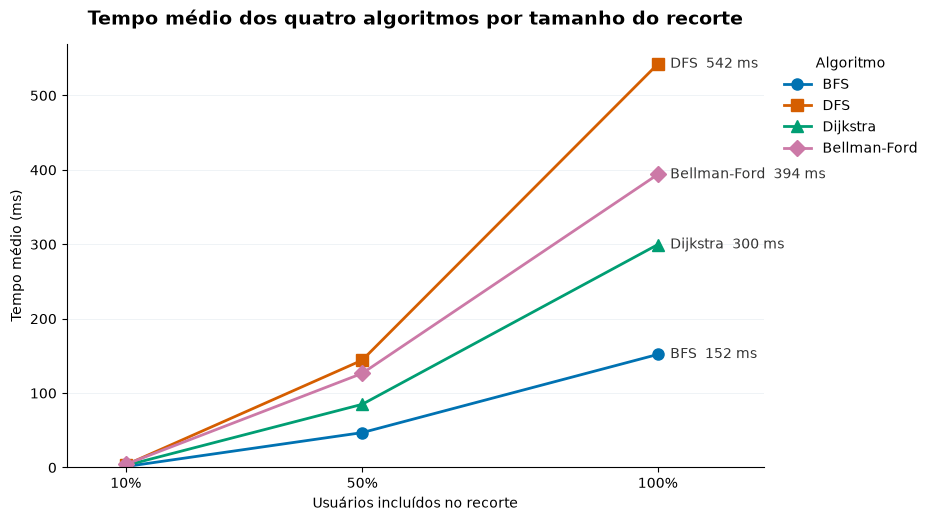

recorte_percentual,10,50,100
algoritmo,,,
BFS,1.265,46.868,151.947
Bellman-Ford,4.166,126.479,393.813
DFS,3.463,144.212,542.144
Dijkstra,2.690,84.896,299.514


In [4]:
# [IA] Claude – código do gráfico de linhas dos tempos médios por recorte
import json

import matplotlib.pyplot as plt
import pandas as pd

CORES_ALGORITMOS = {"BFS": "#0072B2", "DFS": "#D55E00", "Dijkstra": "#009E73", "Bellman-Ford": "#CC79A7"}
MARCADORES = {"BFS": "o", "DFS": "s", "Dijkstra": "^", "Bellman-Ford": "D"}
pasta_figuras = pasta_projeto / "out" / "parte2"

relatorio = json.loads((pasta_figuras / "parte2_report.json").read_text(encoding="utf-8"))
medicoes_escala = pd.DataFrame(
    [m for m in relatorio["medicoes"] if m["tarefa"] == "escalabilidade nos recortes"]
)
# média de todas as execuções (3 usuários de partida x 5 execuções) por algoritmo e recorte, como na seção 9.2
tempos_medios = (
    medicoes_escala.explode("tempos_ms")
    .astype({"tempos_ms": float})
    .groupby(["algoritmo", "recorte_percentual"])["tempos_ms"]
    .mean()
    .unstack("recorte_percentual")
)

fig, ax = plt.subplots(figsize=(9, 5.5), facecolor="white")
for algoritmo, cor in CORES_ALGORITMOS.items():
    serie = tempos_medios.loc[algoritmo]
    ax.plot(serie.index, serie.values, color=cor, marker=MARCADORES[algoritmo],
            markersize=8, linewidth=2, label=algoritmo)
    # nome ao lado do último ponto, além da legenda
    ax.annotate(f"{algoritmo}  {serie.values[-1]:.0f} ms", (serie.index[-1], serie.values[-1]), xytext=(9, 0),
                textcoords="offset points", va="center", fontsize=10, color="#333333")

ax.set_xticks([10, 50, 100], ["10%", "50%", "100%"])
ax.set_xlim(0, 118)
ax.set_ylim(bottom=0)
ax.set_xlabel("Usuários incluídos no recorte")
ax.set_ylabel("Tempo médio (ms)")
ax.set_title("Tempo médio dos quatro algoritmos por tamanho do recorte", fontsize=14, fontweight="bold", pad=14)
ax.legend(title="Algoritmo", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", color="#EDF1F5", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.savefig(pasta_figuras / "alg_tempo_recortes.png", dpi=150, facecolor="white", bbox_inches="tight")
plt.show()

tempos_medios.round(3)

**Nota analítica**

**O que está sendo mostrado.** Cada linha é um algoritmo, e cada ponto é o tempo médio de 15 execuções. Dijkstra e Bellman-Ford usaram peso 1 para amigo e 2 para inimigo.

**Insight.** Nos recortes de 50% e 100%, a ordem do mais lento ao mais rápido foi DFS, Bellman-Ford, Dijkstra e BFS. Na rede completa, os tempos foram de cerca de 542, 394, 300 e 152 ms.

**Por que este tipo de gráfico.** As linhas facilitam acompanhar cada algoritmo pelos três recortes, e a escala linear compara as diferenças em milissegundos, embora deixe os quatro pontos de 10% muito próximos.

### 12.2 Profundidade da BFS e da DFS

**Pergunta:** até quantos passos chegam a BFS e a DFS partindo do mesmo usuário?

Visualização de comparação dos algoritmos 2. Para cada usuário de partida e recorte da seção 6.3, o ponto da BFS mostra a maior distância mínima encontrada, e o da DFS mostra o ramo mais profundo da árvore de busca. Os dois máximos podem corresponder a usuários diferentes. Os valores vão de 1 a 6.636 passos, por isso o eixo vertical usa escala logarítmica. Os usuários de partida aparecem no gráfico como **Usuário A** (48088), **Usuário B** (4710) e **Usuário C** (1199). A figura é salva em `out/parte2/alg_profundidade_buscas.png`.

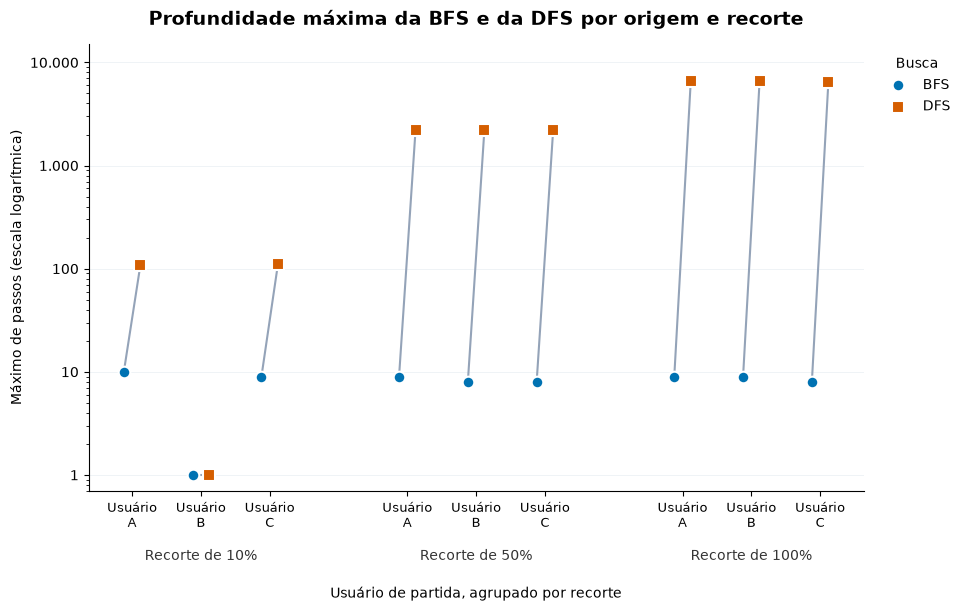

,Recorte (%),Usuário de partida,No gráfico,BFS (máximo de passos),DFS (máximo de passos)
0,10,48088,Usuário A,10,108
1,10,4710,Usuário B,1,1
2,10,1199,Usuário C,9,111
3,50,48088,Usuário A,9,2232
4,50,4710,Usuário B,8,2205
5,50,1199,Usuário C,8,2223
6,100,48088,Usuário A,9,6636
7,100,4710,Usuário B,9,6591
8,100,1199,Usuário C,8,6498


In [5]:
# [IA] Claude – código do gráfico de pontos pareados da profundidade da BFS e da DFS
from src.graphs.algorithms import bfs, dfs

# os mesmos três usuários de partida da seção 6.3, lidos do relatório
fontes_grafico = list(dict.fromkeys(
    m["usuario_partida"] for m in relatorio["medicoes"]
    if m["algoritmo"] == "BFS" and m["tarefa"] == "escalabilidade nos recortes"
))

linhas_profundidade = []
for percentual, grafo in recortes.items():
    for fonte in fontes_grafico:
        distancias, _, _ = bfs(grafo, fonte)
        pais_dfs, ordem_dfs, _, _ = dfs(grafo, fonte)
        # na ordem de visita, o pai de cada usuário já tem profundidade calculada
        passos_dfs = {fonte: 0}
        for usuario in ordem_dfs[1:]:
            passos_dfs[usuario] = passos_dfs[pais_dfs[usuario]] + 1
        linhas_profundidade.append({
            "Recorte (%)": percentual,
            "Usuário de partida": fonte,
            "BFS (máximo de passos)": max(distancias.values()),
            "DFS (máximo de passos)": max(passos_dfs.values()),
        })
profundidade = pd.DataFrame(linhas_profundidade)
# [IA] Claude – rótulos Usuário A, B e C no lugar dos IDs (decisão do grupo)
rotulo_usuario = {fonte: f"Usuário {letra}" for fonte, letra in zip(fontes_grafico, "ABCDEFGH")}
profundidade.insert(2, "No gráfico", profundidade["Usuário de partida"].map(rotulo_usuario))

fig, ax = plt.subplots(figsize=(10, 5.8), facecolor="white")
posicoes, rotulos = [], []
for i, linha in profundidade.iterrows():
    grupo, ordem_no_grupo = divmod(i, len(fontes_grafico))
    x = grupo * (len(fontes_grafico) + 1) + ordem_no_grupo
    posicoes.append(x)
    rotulos.append(rotulo_usuario[linha["Usuário de partida"]].replace(" ", "\n"))
    bfs_max, dfs_max = linha["BFS (máximo de passos)"], linha["DFS (máximo de passos)"]
    ax.plot([x - 0.12, x + 0.12], [bfs_max, dfs_max], color="#94A3B8", linewidth=1.5, zorder=1)
    ax.scatter(x - 0.12, bfs_max, s=70, marker="o", color=CORES_ALGORITMOS["BFS"],
               edgecolor="white", linewidth=1.5, zorder=3, label="BFS" if i == 0 else None)
    ax.scatter(x + 0.12, dfs_max, s=70, marker="s", color=CORES_ALGORITMOS["DFS"],
               edgecolor="white", linewidth=1.5, zorder=3, label="DFS" if i == 0 else None)

ax.set_yscale("log")
ax.set_ylim(0.7, 15000)
ax.set_yticks([1, 10, 100, 1000, 10000], ["1", "10", "100", "1.000", "10.000"])
ax.set_xticks(posicoes, rotulos, fontsize=9)
for grupo, percentual in enumerate(recortes):
    centro = grupo * (len(fontes_grafico) + 1) + (len(fontes_grafico) - 1) / 2
    ax.text(centro, -0.13, f"Recorte de {percentual}%", transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=10, color="#333333")
ax.set_xlabel("Usuário de partida, agrupado por recorte", labelpad=40)
ax.set_ylabel("Máximo de passos (escala logarítmica)")
ax.set_title("Profundidade máxima da BFS e da DFS por origem e recorte", fontsize=14, fontweight="bold", pad=14)
ax.legend(title="Busca", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.grid(axis="y", color="#EDF1F5", linewidth=0.6)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.savefig(pasta_figuras / "alg_profundidade_buscas.png", dpi=150, facecolor="white", bbox_inches="tight")
plt.show()

profundidade

**Nota analítica**

**O que está sendo mostrado.** Cada par compara a maior distância mínima da BFS com o ramo mais profundo da DFS, para a mesma origem e o mesmo recorte. Os dois máximos podem ser de usuários diferentes.

**Insight.** Nos nove casos, a BFS ficou entre 1 e 10 passos, enquanto a DFS chegou a 6.636. Por isso a BFS mede a menor volta. Na seção 6.2, ela encontrou 2 passos para o mesmo destino que a DFS alcançou em 775.

**Por que este tipo de gráfico.** Os pontos pareados comparam as duas buscas em cada caso, e a escala logarítmica mantém visíveis os valores de 1 a 6.636. Nessa escala, intervalos iguais representam a mesma proporção.

### 12.3 Passos da volta no piloto

**Pergunta:** o caminho de menor custo do Dijkstra tem o mesmo número de passos que a volta da BFS?

Visualização de comparação dos algoritmos 3. Usamos as mesmas 10 marcações das seções 6.1 e 7.1. A marcação sem volta aparece como categoria própria, sem barra, porque uma barra de tamanho zero indicaria que quem marcou e quem recebeu são a mesma pessoa. A figura é salva em `out/parte2/alg_passos_volta_piloto.png`.

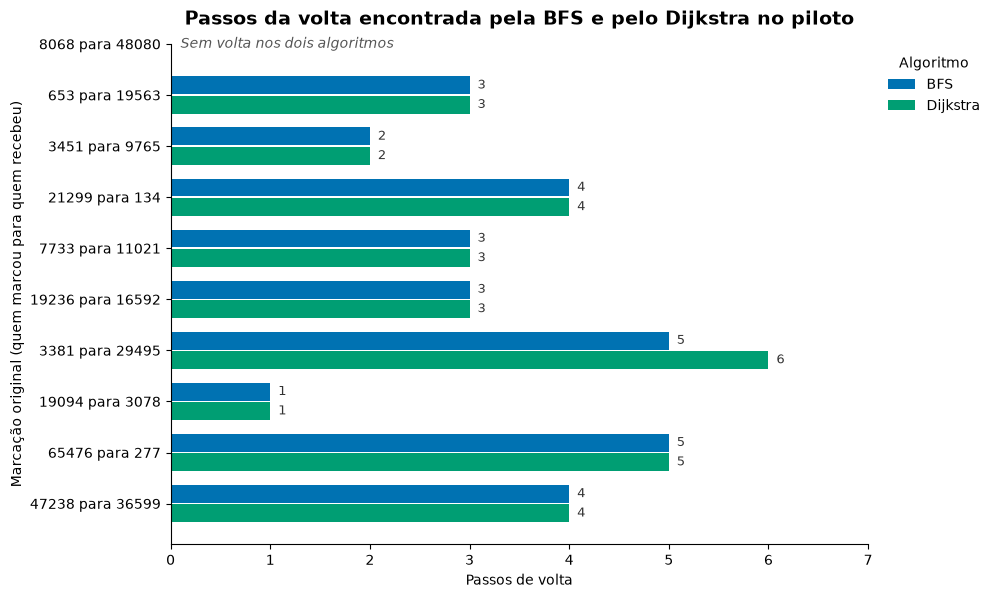

,Marcação,BFS (passos),Dijkstra (passos)
0,8068 para 48080,<NA>,<NA>
1,653 para 19563,3,3
2,3451 para 9765,2,2
3,21299 para 134,4,4
4,7733 para 11021,3,3
5,19236 para 16592,3,3
6,3381 para 29495,5,6
7,19094 para 3078,1,1
8,65476 para 277,5,5
9,47238 para 36599,4,4


In [6]:
# [IA] Claude – código do gráfico de barras horizontais agrupadas dos passos de volta no piloto
from src.graphs.algorithms import bfs

# as dez marcações do piloto, na mesma ordem das seções 6.1 e 7.1
linhas_piloto = []
for m in relatorio["medicoes"]:
    if m["tarefa"] != "volta das marcações do piloto":
        continue
    recebeu, marcou = m["usuario_partida"], m["destino"]
    distancias, _, _ = bfs(grafo_completo, recebeu)
    linhas_piloto.append({
        "Marcação": f"{marcou} para {recebeu}",
        "BFS (passos)": distancias.get(marcou),
        "Dijkstra (passos)": m["passos"],
    })
passos_piloto = pd.DataFrame(linhas_piloto).astype({"BFS (passos)": "Int64", "Dijkstra (passos)": "Int64"})

fig, ax = plt.subplots(figsize=(9, 6.5), facecolor="white")
altura = 0.38
for i, linha in passos_piloto.iterrows():
    if pd.isna(linha["BFS (passos)"]) and pd.isna(linha["Dijkstra (passos)"]):
        ax.text(0.1, i, "Sem volta nos dois algoritmos", va="center", fontsize=10, color="#555555", style="italic")
        continue
    for deslocamento, coluna, nome in ((-altura / 2, "BFS (passos)", "BFS"), (altura / 2, "Dijkstra (passos)", "Dijkstra")):
        valor = int(linha[coluna])
        ax.barh(i + deslocamento, valor, height=altura * 0.92, color=CORES_ALGORITMOS[nome],
                label=nome if nome not in ax.get_legend_handles_labels()[1] else None)
        ax.text(valor + 0.08, i + deslocamento, str(valor), va="center", fontsize=9, color="#333333")

ax.set_yticks(range(len(passos_piloto)), passos_piloto["Marcação"])
ax.invert_yaxis()
ax.set_xlim(0, 7)
ax.set_xticks(range(0, 8))
ax.set_xlabel("Passos de volta")
ax.set_ylabel("Marcação original (quem marcou para quem recebeu)")
ax.set_title("Passos da volta encontrada pela BFS e pelo Dijkstra no piloto", fontsize=14, fontweight="bold", pad=14)
ax.legend(title="Algoritmo", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.savefig(pasta_figuras / "alg_passos_volta_piloto.png", dpi=150, facecolor="white", bbox_inches="tight")
plt.show()

passos_piloto

**Nota analítica**

**O que está sendo mostrado.** Cada par de barras compara os passos de volta da BFS e do Dijkstra para uma marcação. A de 8068 para 48080 aparece sem barra porque nenhum dos dois encontrou volta.

**Insight.** Das nove marcações com volta, oito tiveram o mesmo número de passos, e só a de 3381 para 29495 passou de 5 na BFS para 6 no Dijkstra. Em três das oito, os caminhos passaram por usuários diferentes, como mostram as seções 6.1 e 7.1.

**Por que este tipo de gráfico.** As barras agrupadas comparam os dois valores de cada marcação, e a orientação horizontal deixa espaço para ler os identificadores dos usuários.

## 13. Discussão crítica

### 13.1 Quando usar cada algoritmo

A BFS responde à pergunta de pesquisa porque visita os usuários por número de passos, e a primeira vez que alcança quem fez a marcação determina a menor volta possível. A DFS serve para explorar ramos, classificar arcos e detectar ciclos. A seção 6.2 mostra a diferença: na volta de 9765 até 3451, a BFS encontrou 2 passos, e o caminho registrado pela DFS teve 775.

O Dijkstra é adequado para minimizar um custo com pesos não negativos. O Bellman-Ford trabalha com os sinais originais e detecta ciclos negativos alcançáveis. Na seção 9.1, com os mesmos pesos positivos, os dois calcularam os mesmos custos nos nove casos, e o Dijkstra teve o menor tempo médio em todos.

### 13.2 Limites do design de pesos

Dar peso 1 a amigo e 2 a inimigo faz uma marcação de inimigo custar tanto quanto duas de amigo. É uma escolha do grupo para penalizar esse tipo de marcação. Na seção 7.1, isso mudou a volta de 29495 até 3381: o caminho da BFS tinha cinco passos e custo sete, e o do Dijkstra, seis passos e custo seis. O dataset registra a categoria da marcação, sem medir sua intensidade.

Somar os sinais originais também tem limites. Um custo zero pode reunir uma marcação de cada tipo sem revelar o que os usuários das pontas pensam um do outro. No ciclo entre 919 e 949, cada volta desconta mais dois ao contar de novo as mesmas marcações. Por isso, partindo de 11038, não existe custo mínimo finito para os destinos alcançáveis depois desse ciclo.

### 13.3 Resposta à pergunta de pesquisa

Na amostra, as marcações de amigo tiveram mais voltas diretas, e as de inimigo, mais voltas de três passos. Entre as 1.000 marcações de cada grupo, 22,5% das de amigo e 9,8% das de inimigo tiveram volta direta, e em três passos foram 15,0% e 24,8%. Ficaram sem volta 37,8% das de amigo e 33,1% das de inimigo, e entre os casos com volta a mediana foi de três passos nos dois grupos. Esses números estão nas seções 8.1 e 8.2 do notebook 01, e a seção 9.1 de lá mostra que, quando o destinatário nunca marcou ninguém, nenhuma volta foi possível.

A conclusão vale para caminhos que seguem a direção das marcações e para a amostra de 2.000 casos, 0,36% do dataset. A divisão em metades permite comparar os tipos, mas uma estimativa para a rede inteira precisaria considerar a proporção real de cada tipo.